In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans


In [2]:
np.random.seed(0)
n = 200
df = pd.DataFrame(
    {
        "CustomerID": range(1, n + 1),
        "Gender": np.random.choice(["Male", "Female"], n),
        "Age": np.random.randint(18, 70, n),
        "Annual Income (k$)": np.random.randint(15, 140, n),
        "Spending Score (1-100)": np.random.randint(1, 100, n),
    }
)
print(df.info())
print(df.head())


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int32
 3   Annual Income (k$)      200 non-null    int32
 4   Spending Score (1-100)  200 non-null    int32
dtypes: int32(3), int64(1), str(1)
memory usage: 5.6 KB
None
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   20                 102                      52
1           2  Female   21                  28                      74
2           3  Female   48                  73                      54
3           4    Male   52                  96                      70
4           5  Female   61                 135                      34


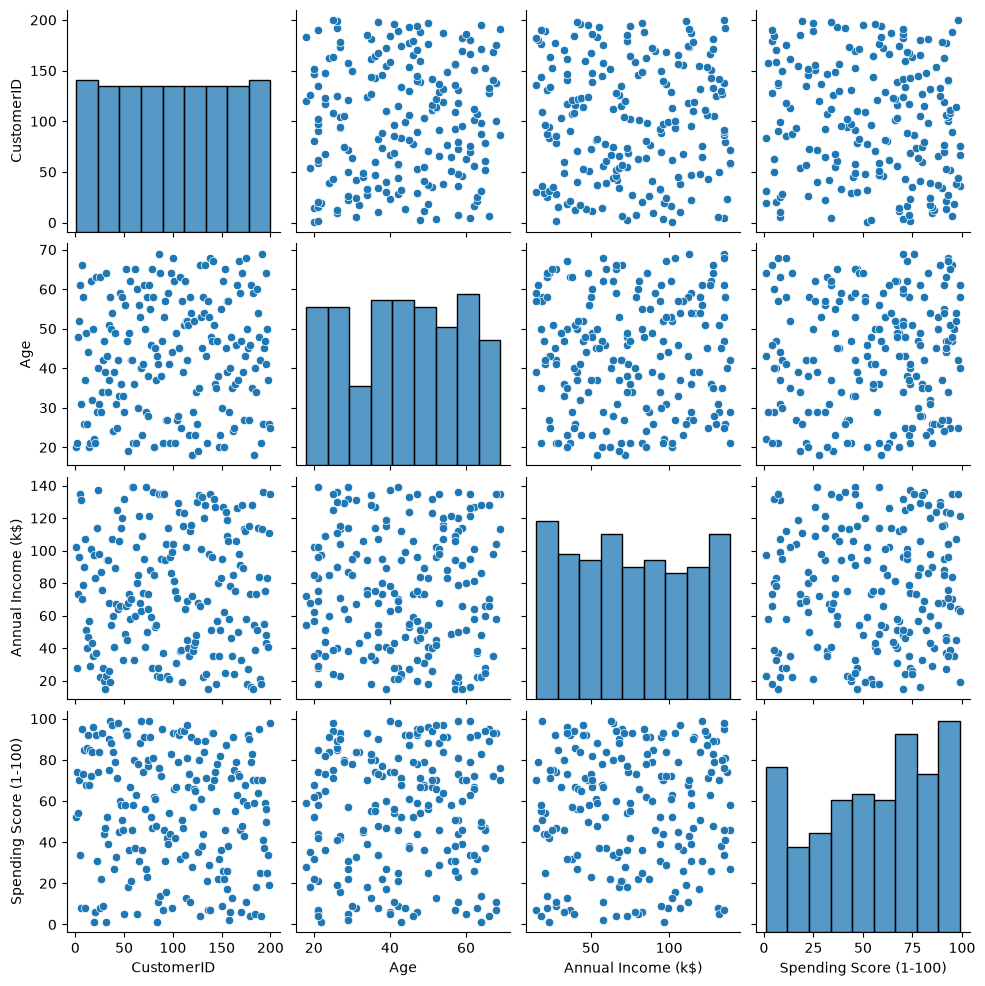

In [3]:
sns.pairplot(df)
plt.show()


In [4]:
features = df.iloc[:, [3, 4]].values
model = KMeans(n_clusters=5, n_init=10, random_state=0)
model.fit(features)
Final = df.iloc[:, [3, 4]].copy()
Final["label"] = model.predict(features)
print(Final.head())


   Annual Income (k$)  Spending Score (1-100)  label
0                 102                      52      0
1                  28                      74      1
2                  73                      54      4
3                  96                      70      4
4                 135                      34      0


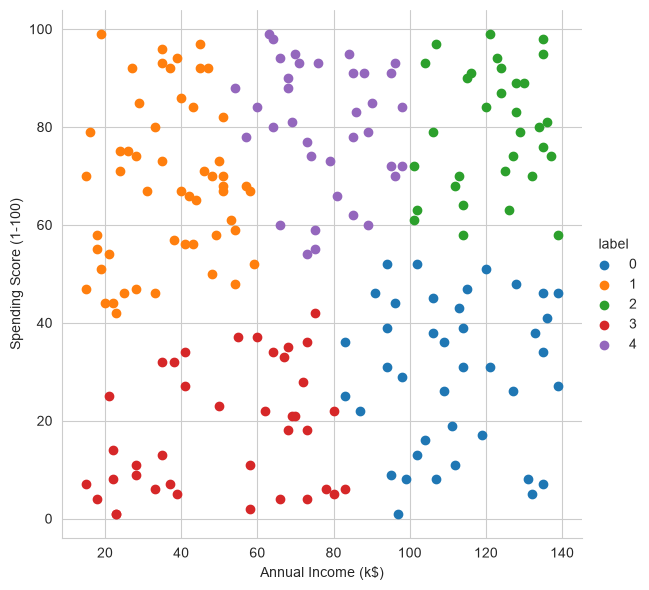

In [5]:
sns.set_style("whitegrid")
sns.FacetGrid(Final, hue="label", height=6).map(
    plt.scatter, "Annual Income (k$)", "Spending Score (1-100)"
).add_legend()
plt.show()


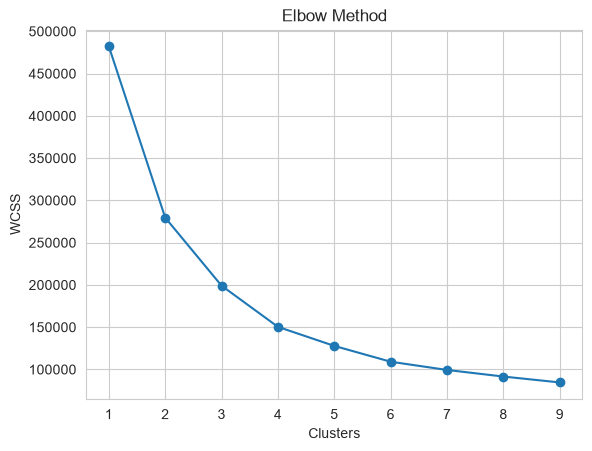

In [6]:
features_el = df.iloc[:, [2, 3, 4]].values
wcss = []
for i in range(1, 10):
    m = KMeans(n_clusters=i, n_init=10, random_state=0)
    m.fit(features_el)
    wcss.append(m.inertia_)
plt.plot(range(1, 10), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Clusters")
plt.ylabel("WCSS")
plt.show()
